## Human Population density

Population density shape: (180, 360)
Affine transform: | 1.00, 0.00,-180.00|
| 0.00,-1.00, 90.00|
| 0.00, 0.00, 1.00|
CRS: EPSG:4326
Bounds: BoundingBox(left=-180.0, bottom=-90.00000000000009, right=180.0, top=89.99999999999991)


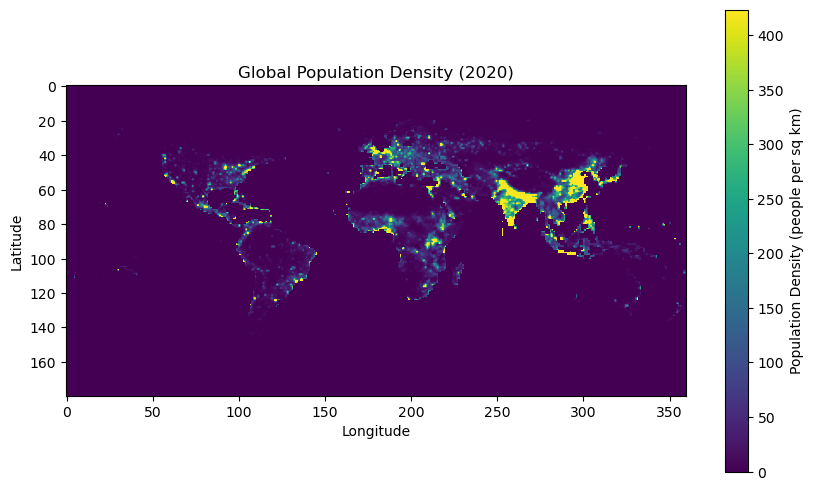

In [5]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import os

path = os.path.expanduser('~/Func_Neo_Phytes/Data/gpw_v4_population_density_rev11_2020_1_deg.tif')

with rasterio.open(path) as src:
    population_density = src.read(1)
    transform = src.transform
    crs = src.crs
    bounds = src.bounds

    print(f"Population density shape: {population_density.shape}")
    print(f"Affine transform: {transform}")
    print(f"CRS: {crs}")
    print(f"Bounds: {bounds}")

plt.figure(figsize=(10, 6))
plt.imshow(
    population_density,
    cmap='viridis',
    vmin=0,
    vmax=np.percentile(population_density, 99)
)
plt.colorbar(label='Population Density (people per sq km)')
plt.title('Global Population Density (2020)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [ ]:
# convert to h3 grid
import h3
resolution = 3
h3_grid = h3.geo_to_h3(bounds.top, bounds.left, resolution)
print(f"H3 grid index for top-left corner: {h3_grid}")
h3_grid = h3.geo_to_h3(bounds.bottom, bounds.right, resolution)
print(f"H3 grid index for bottom-right corner: {h3_grid}")  


In [10]:
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import xy
import os
import h3.api.numpy_int as h3np

path = os.path.expanduser('~/Func_Neo_Phytes/Data/gpw_v4_population_density_rev11_2020_1_deg.tif')

with rasterio.open(path) as src:
    pop = src.read(1)
    transform = src.transform
    nodata = src.nodata

# get coordinates
rows, cols = np.indices(pop.shape)
xs, ys = xy(transform, rows, cols)

xs = np.array(xs)
ys = np.array(ys)

# flatten
lon = xs.flatten()
lat = ys.flatten()
values = pop.flatten()

# clean
mask = np.isfinite(values)
if nodata is not None:
    mask &= values != nodata

lon = lon[mask]
lat = lat[mask]
values = values[mask]

# H3 indexing (FAST)
#h3_cells = h3np.latlng_to_cell(lat, lon, 3)
#h3_cells = h3np.geo_to_h3(lat, lon, 3)
h3_cells = np.array([
    format(h3np.geo_to_h3(lat[i], lon[i], 3), 'x')
    for i in range(len(lat))
])

# aggregate mean density
df = pd.DataFrame({
    "h3": h3_cells,
    "density": values
})

h3_mean = df.groupby("h3")["density"].mean().reset_index()

In [11]:
h3_mean

,h3,density
0,830001fffffffff,0.081605
1,830005fffffffff,0.122407
2,83000cfffffffff,0.061204
3,830011fffffffff,0.036079
4,830018fffffffff,0.036079
...,...,...
12867,83df6afffffffff,4.538659
12868,83df6bfffffffff,0.769192
12869,83df6cfffffffff,3.837568
12870,83df6dfffffffff,6.028785


In [12]:
# save h3_mean to csv
h3_mean.to_csv(os.path.expanduser('~/Func_Neo_Phytes/Data/h3_population_density.csv'), index=False)